In [2]:
# Import the libraries we need
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Show all columns when we print a table
pd.set_option("display.max_columns", 50)

# Folders
MODEL_DIR = "../models/"
DATA_DIR = "../data/processed/"

# Load the three fitted models from Notebook 03
models = {
    "Ridge": joblib.load(MODEL_DIR + "ridge_model.joblib"),
    "Random Forest": joblib.load(MODEL_DIR + "random_forest_model.joblib"),
    "XGBoost": joblib.load(MODEL_DIR + "xgboost_model.joblib"),
}

# Load the split details, and the train and test tables
with open(MODEL_DIR + "split_info.json") as f:
    split_info = json.load(f)
train = pd.read_csv(DATA_DIR + "train_80.csv")
test = pd.read_csv(DATA_DIR + "test_20_untouched.csv")

# Features and target (same names as in Notebook 03)
FEATURES = split_info["features"]
TARGET = split_info["target"]
X_test, y_test = test[FEATURES], test[TARGET]

print("Models loaded:", list(models))
print("Test shape:", test.shape)
print("Number of features:", len(FEATURES))



Models loaded: ['Ridge', 'Random Forest', 'XGBoost']
Test shape: (1076, 37)
Number of features: 32


In [3]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Real prices in Rupees (price at the 2025-H1 level)
price_true = np.exp(y_test)

# Predict with each model (the model gives log price, so we use exp to get Rupees)
preds_log = {name: m.predict(X_test) for name, m in models.items()}
preds_rs = {name: np.exp(p) for name, p in preds_log.items()}

# All the metrics for one model
def full_score(name):
    p_log, p_rs = preds_log[name], preds_rs[name]
    ape = np.abs(price_true - p_rs) / price_true * 100   # % error of each row
    return {
        "R2": r2_score(y_test, p_log),
        "RMSE_log": np.sqrt(mean_squared_error(y_test, p_log)),
        "MAE_log": mean_absolute_error(y_test, p_log),
        "MAPE_%": ape.mean(),
        "Median_APE_%": ape.median(),
        "Within_20%": (ape <= 20).mean() * 100,
        "Within_30%": (ape <= 30).mean() * 100,
    }

# Final test table
test_table = pd.DataFrame({name: full_score(name) for name in models}).T
print("FINAL TEST RESULTS (untouched 20% test set):")
print(test_table.round(3))


FINAL TEST RESULTS (untouched 20% test set):
                  R2  RMSE_log  MAE_log  MAPE_%  Median_APE_%  Within_20%  \
Ridge          0.822     0.436    0.280  35.349        17.575      55.390   
Random Forest  0.893     0.338    0.200  23.422        10.444      67.751   
XGBoost        0.898     0.329    0.207  23.597        11.621      65.149   

               Within_30%  
Ridge              68.773  
Random Forest      78.253  
XGBoost            78.160  


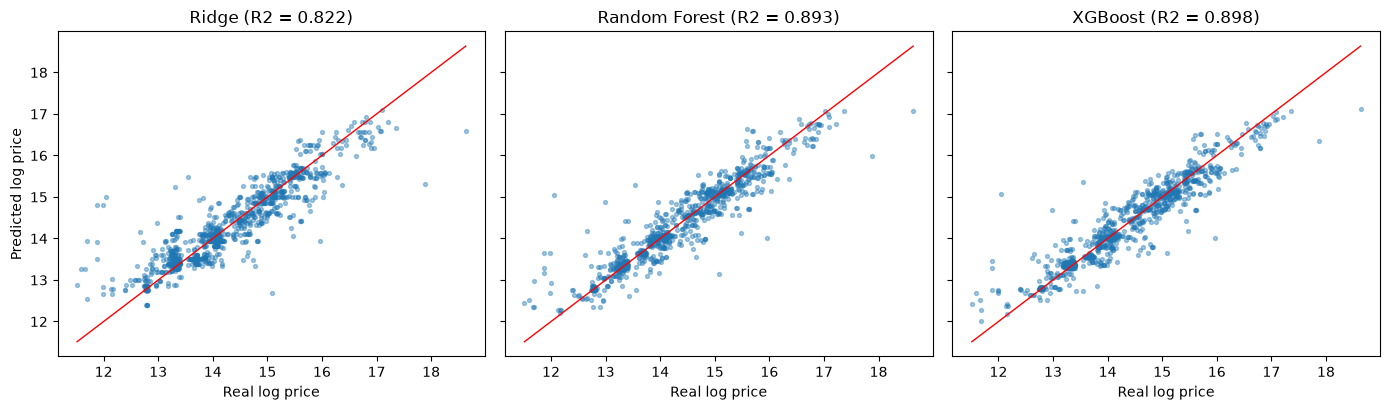

In [4]:
# Plot predicted vs real price (log scale) for each model
# Points close to the red line mean good predictions
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)

for a, name in zip(ax, models):
    a.scatter(y_test, preds_log[name], s=8, alpha=0.4)
    lims = [y_test.min(), y_test.max()]
    a.plot(lims, lims, color="red", linewidth=1)
    a.set_title(f"{name} (R2 = {test_table.loc[name, 'R2']:.3f})")
    a.set_xlabel("Real log price")

ax[0].set_ylabel("Predicted log price")
plt.tight_layout()
plt.show()


In [6]:
# Split the test rows into 5 groups by real price (cheapest to most expensive)
bands = pd.qcut(price_true, 5, labels=["Lowest", "Low", "Middle", "High", "Highest"])
band_names = list(bands.cat.categories)

rows = []
for name in models:
    ape = np.abs(price_true - preds_rs[name]) / price_true * 100
    # Signed error: negative means the model predicted too low
    signed = (preds_rs[name] - price_true) / price_true * 100
    for band in band_names:
        m = (bands == band)
        rows.append({"Model": name, "Price band": band,
                     "Rows": int(m.sum()),
                     "Median_APE_%": ape[m].median(),
                     "Median_signed_error_%": signed[m].median()})

band_table = pd.DataFrame(rows)

# Show Median APE and the bias, one column per model
print("Median absolute % error by price band:")
print(band_table.pivot(index="Price band", columns="Model",
                       values="Median_APE_%").loc[band_names].round(1))
print("\nMedian signed % error (negative = predicted too low):")
print(band_table.pivot(index="Price band", columns="Model",
                       values="Median_signed_error_%").loc[band_names].round(1))

# Price range of each band, in Rupees
print("\nPrice range of each band (Rs per perch):")
print(price_true.groupby(bands, observed=True).agg(["min", "max"]).round(0))


Median absolute % error by price band:
Model       Random Forest  Ridge  XGBoost
Price band                               
Lowest                6.9   22.5      8.7
Low                   7.6   17.2      9.2
Middle                6.4   12.8      6.9
High                 17.2   19.2     18.9
Highest              18.0   21.5     20.0

Median signed % error (negative = predicted too low):
Model       Random Forest  Ridge  XGBoost
Price band                               
Lowest                3.2   19.7      7.0
Low                   0.5   -0.5     -2.2
Middle               -2.5   -8.3     -3.7
High                 -0.7   -7.5     -1.3
Highest              -9.8  -11.6    -11.5

Price range of each band (Rs per perch):
                     min          max
log_price_adj                        
Lowest          100000.0     612121.0
Low             612420.0    1169368.0
Middle         1171842.0    1868021.0
High           1876441.0    3932643.0
Highest        3934655.0  123755228.0


In [7]:
# Save the final test table and the price band table
test_table.round(4).to_csv("../reports/tables/04_test_results.csv")
band_table.round(3).to_csv("../reports/tables/04_test_by_price_band.csv", index=False)

# Save each test row with real price and the three predictions
out = test[["Address_ID", "Address", "date", "period"]].copy()
out["real_price"] = price_true.round(0)
for name in models:
    out["pred_" + name.lower().replace(" ", "_")] = preds_rs[name].round(0)
out.to_csv("../reports/tables/04_test_predictions.csv", index=False)

# Test rows from areas that are not in the training data
train_areas = set(train["Address_ID"])
unseen = ~test["Address_ID"].isin(train_areas)
print("Test rows in areas not seen in training:", int(unseen.sum()), "of", len(test))

print("\nSaved:")
import os
print(sorted(f for f in os.listdir("../reports/tables") if f.startswith("04_")))


Test rows in areas not seen in training: 2 of 1076

Saved:
['04_test_by_price_band.csv', '04_test_predictions.csv', '04_test_results.csv']
